In [1]:
import torch
import matplotlib.pyplot as plt

In [16]:
temp_at_cel = [15.0 , 30.0 , 45.0 , 60.0 , 75.0 , 90.0 ]
temp_at_vin = [10.0 , 20.0 , 30.0 , 40.0 , 50.0 , 60.0 ]
print('The given temp is' , temp_at_cel)
print("The new scale is" , temp_at_vin)

The given temp is [15.0, 30.0, 45.0, 60.0, 75.0, 90.0]
The new scale is [10.0, 20.0, 30.0, 40.0, 50.0, 60.0]


In [48]:
temp_at_cel = torch.tensor(temp_at_cel)
temp_at_vin = torch.tensor(temp_at_vin)
print (temp_at_cel)
print(temp_at_vin)

tensor([15., 30., 45., 60., 75., 90.])
tensor([10., 20., 30., 40., 50., 60.])


/tmp/ipykernel_1278/1217215230.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  temp_at_cel = torch.tensor(temp_at_cel)
/tmp/ipykernel_1278/1217215230.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  temp_at_vin = torch.tensor(temp_at_vin)


In [49]:
def model (temp_at_cel ,w , b):
 return w*temp_at_cel + b

In [50]:
def loss_fn(temp_pre, temp_at_vin):
 return torch.mean((temp_pre - temp_at_vin)**2)

In [40]:
w = torch.ones((), requires_grad = True)
b = torch.zeros((), requires_grad = True)
temp_pre = model(temp_at_vin , w, b)
temp_pre

tensor([10., 20., 30., 40., 50., 60.], grad_fn=<AddBackward0>)

In [41]:
optimizer = torch.optim.SGD([w, b], lr=1e-4)

n_epochs = 5
loss_values = []

for epoch in range(n_epochs):
    temp_pre = model(temp_at_cel, w, b) # Make sure to use temp_at_cel for prediction
    loss = loss_fn(temp_pre, temp_at_vin)
    loss.backward() # Backpropagation
    optimizer.step() # Update parameters
    optimizer.zero_grad() # Reset gradients to zero

    loss_values.append(loss.item())

    if epoch % 100 == 0:
        print(f'Epoch {epoch}: Loss = {loss.item():.4f}')

Epoch 0: Loss = 379.1667


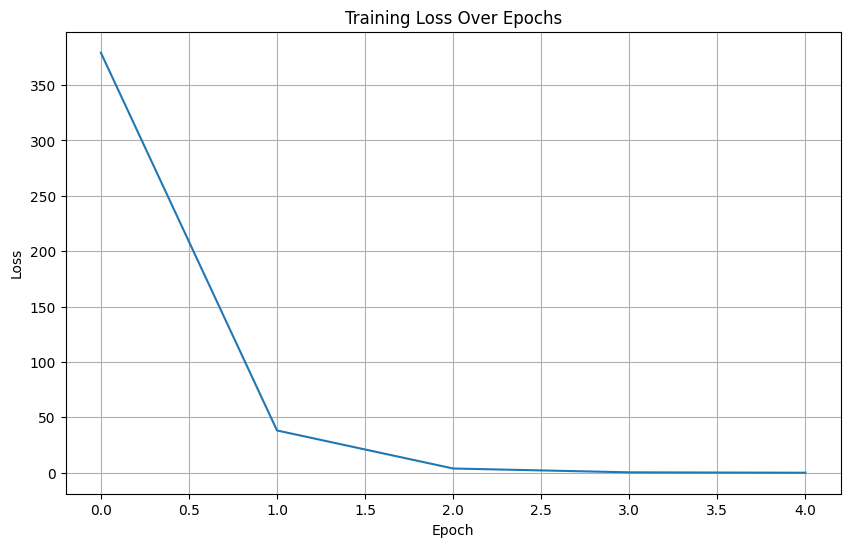

In [42]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), loss_values)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.show()

Let's see the final learned parameters `w` and `b`, and the final predictions.

In [43]:
print(f'Final learned w: {w.item():.4f}')
print(f'Final learned b: {b.item():.4f}')

final_temp_pre = model(temp_at_cel, w, b)
print('Final predicted temperatures:', final_temp_pre.detach().numpy()) # .detach().numpy() to get plain numbers

Final learned w: 0.6678
Final learned b: -0.0051
Final predicted temperatures: [10.01216  20.02943  30.046701 40.06397  50.081238 60.09851 ]


In [51]:
my_temp_at_cel = [25.0, 50.0, 80.0, 100.0]
my_temp_at_cel_tensor = torch.tensor(my_temp_at_cel)

# Get predictions from the trained model
predicted_temp_at_vin = model(my_temp_at_cel_tensor, w, b)

print('Your input temperatures (temp_at_cel):', my_temp_at_cel)
print('Predicted temperatures (temp_at_vin):', predicted_temp_at_vin.detach().numpy())

Your input temperatures (temp_at_cel): [25.0, 50.0, 80.0, 100.0]
Predicted temperatures (temp_at_vin): [16.69034  33.385788 53.42033  66.77669 ]


In [52]:
print('Please inter the temp in cel')
a = int(input())
temp_in_cel_input = a

# Convert to a PyTorch tensor
temp_in_cel_tensor = torch.tensor(temp_in_cel_input)

# Get the prediction from the trained model
predicted_temp_in_vin = model(temp_in_cel_tensor, w, b)

print(f'Input Temperature (Celsius): {temp_in_cel_input}')
print(f'Predicted Temperature (Vin Scale): {predicted_temp_in_vin.item():.2f}')

Please inter the temp in cel
354
Input Temperature (Celsius): 354
Predicted Temperature (Vin Scale): 236.40
